  0%|                                                                                    | 0/6 [00:00<?, ?it/s]

expand後 vessel ラベル数: 7
面積≦5pxのvessel数: 0


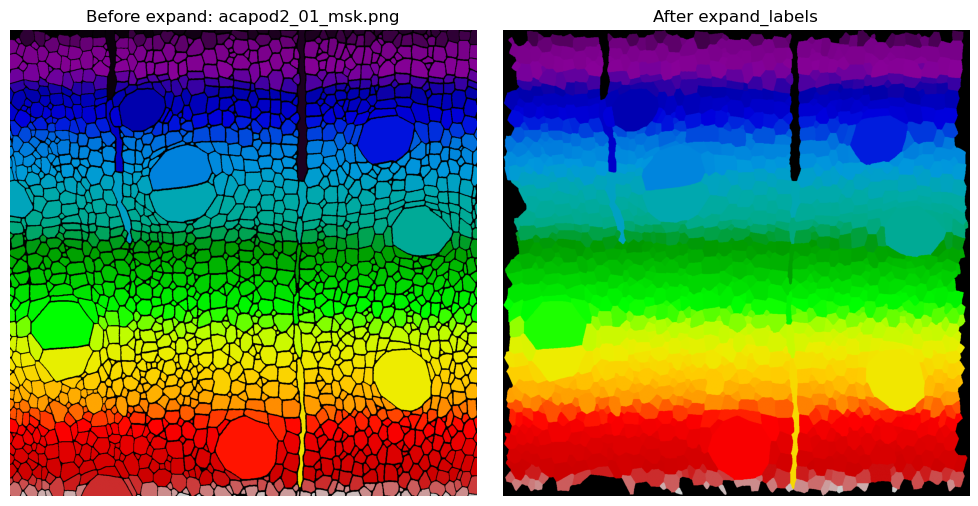

 17%|████████████▋                                                               | 1/6 [00:08<00:40,  8.14s/it]

expand後 vessel ラベル数: 31
面積≦5pxのvessel数: 0


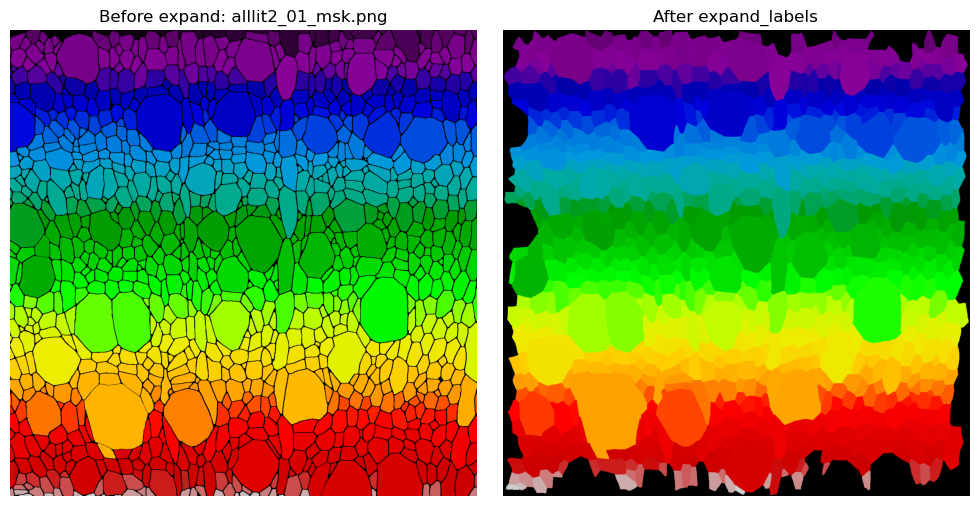

 33%|█████████████████████████▎                                                  | 2/6 [00:16<00:33,  8.35s/it]

expand後 vessel ラベル数: 43
面積≦5pxのvessel数: 0


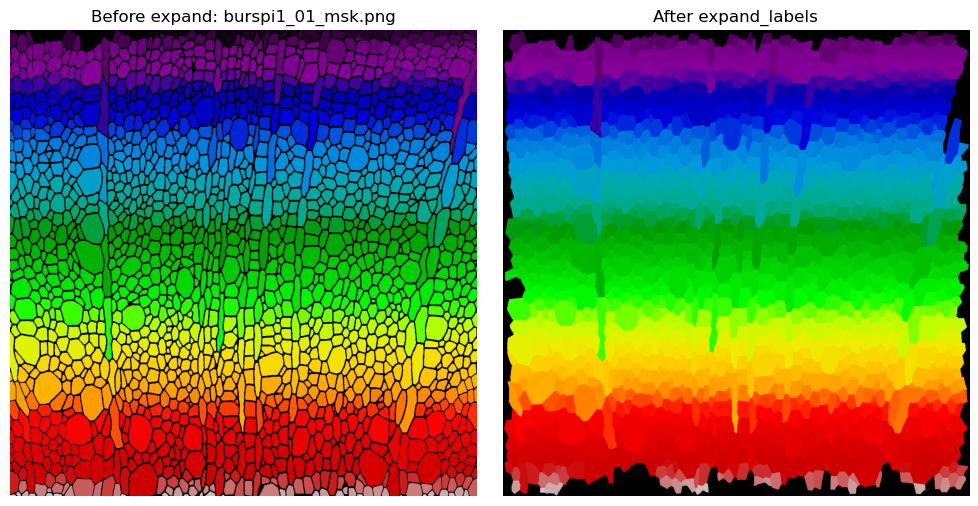

 50%|██████████████████████████████████████                                      | 3/6 [00:21<00:20,  6.93s/it]

expand後 vessel ラベル数: 19
面積≦5pxのvessel数: 0


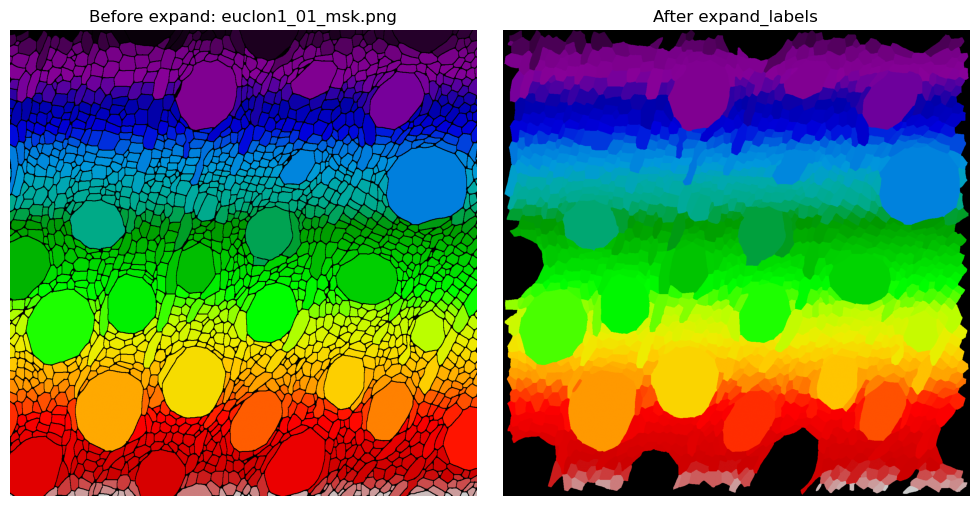

 67%|██████████████████████████████████████████████████▋                         | 4/6 [00:29<00:14,  7.08s/it]

expand後 vessel ラベル数: 7
面積≦5pxのvessel数: 0


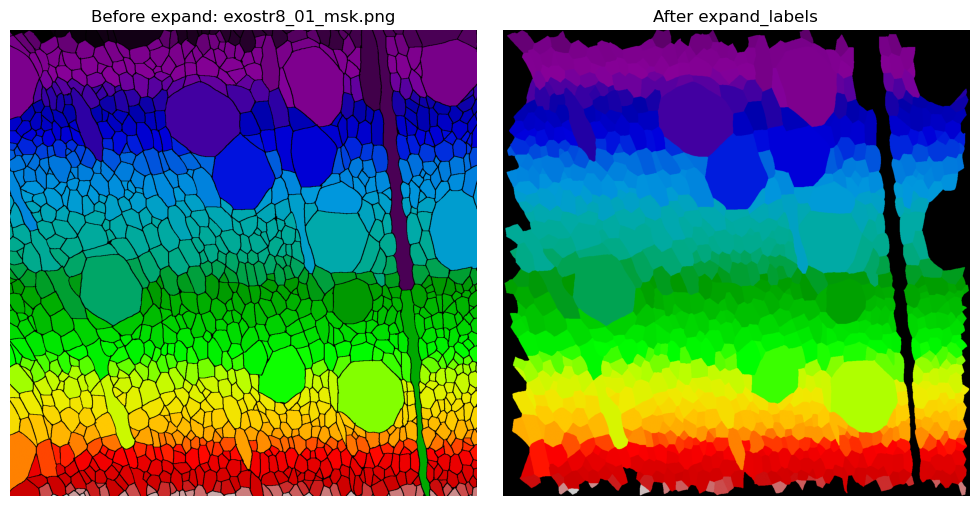

 83%|███████████████████████████████████████████████████████████████▎            | 5/6 [00:37<00:07,  7.59s/it]

expand後 vessel ラベル数: 10
面積≦5pxのvessel数: 0


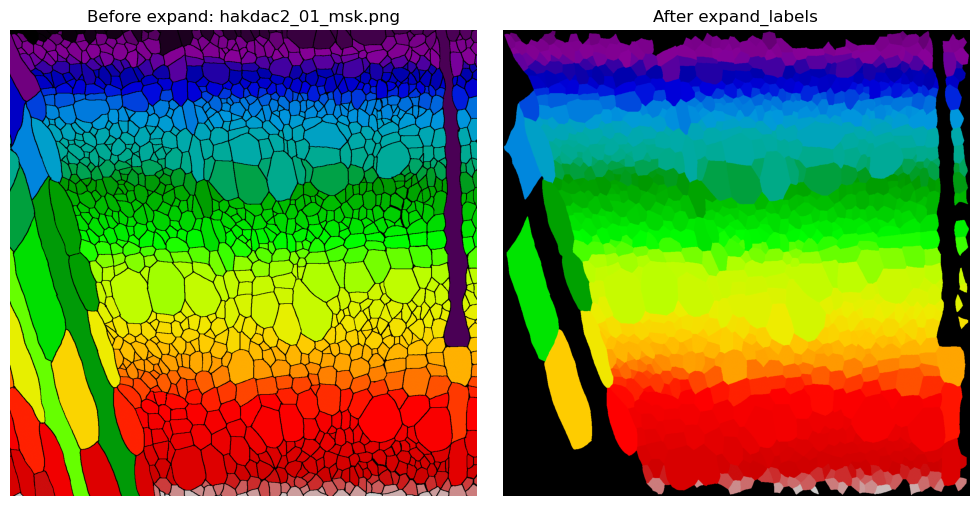

100%|████████████████████████████████████████████████████████████████████████████| 6/6 [00:49<00:00,  8.26s/it]


In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label, regionprops
from skimage.segmentation import expand_labels, find_boundaries, clear_border
from skimage.morphology import dilation, square
from skimage import graph
from collections import defaultdict
from tqdm import tqdm
import networkx as nx
import pickle

## 「vessel–AP（軸方向柔細胞）接触のエッジ一覧データ」 を保存したCSV

# クラス値の定義
CLASS_VALUES = {'vessel': 0, 'ray': 64, 'fiber': 128, 'parenchyma': 192, 'stuff': 255}
V_CLASSES = [CLASS_VALUES['vessel']]
AP_CLASSES = [CLASS_VALUES['parenchyma']]
RAG_CLASSES = V_CLASSES + AP_CLASSES + [CLASS_VALUES['ray']]
VALID_CLASSES = RAG_CLASSES + [CLASS_VALUES['fiber']]

# 入力設定
gt_dir = 'dataset/performance_check/mask'
img_ids = [
    'acapod2_01_msk.png', 'alllit2_01_msk.png', 'burspi1_01_msk.png',
    'euclon1_01_msk.png', 'exostr8_01_msk.png', 'hakdac2_01_msk.png'
]

records = []

for img_id in tqdm(img_ids):
    img_path = os.path.join(gt_dir, img_id)
    mask = np.array(Image.open(img_path).convert('L'))
    # vessel, ray, parenchyma を対象とするマスク（0以外で値を残す）
    rag_mask = np.isin(mask, VALID_CLASSES).astype(np.uint8)
    
    # ラベリングは 0 以外の領域に対して行う
    raw_label = label(rag_mask)
    
    # expand_labels にかけて隙間を埋める
    expanded = expand_labels(raw_label, distance=40)
    # 🔧 境界接触オブジェクトの除去（vesselだけでなく全ラベルに対して）
    expanded = clear_border(expanded)
    
    # ラベル → クラス値のマッピング（post_class_map の定義）
    post_class_map = {}
    for region in regionprops(expanded):
        coords = region.coords
        values = mask[coords[:, 0], coords[:, 1]]  # 元マスク上の画素値を取得
        most_common_class = np.bincount(values).argmax()  # 最頻値を採用
        post_class_map[region.label] = most_common_class


    
    # expand 後のラベル画像に含まれるラベル ID をすべて取得
    unique_labels = np.unique(expanded)
    vessel_mask = np.zeros_like(expanded, dtype=bool)
    
    for label_id in unique_labels:
        if post_class_map.get(label_id, 255) == CLASS_VALUES['vessel']:
            vessel_mask[expanded == label_id] = True
    
    # vesselマスクに対してラベリング
    vessel_labels_post = label(vessel_mask)
    props = regionprops(vessel_labels_post)
    expanded_vessel_ids = np.unique(vessel_labels_post)[1:]
    print(f"expand後 vessel ラベル数: {len(expanded_vessel_ids)}")
    # 面積≦5の vessel を確認
    small_vessels = [p for p in props if p.area <= 5]
    print(f"面積≦5pxのvessel数: {len(small_vessels)}")

    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(raw_label, cmap='nipy_spectral')
    axes[0].set_title(f"Before expand: {img_id}")
    axes[1].imshow(expanded, cmap='nipy_spectral')
    axes[1].set_title("After expand_labels")
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # ラベル → クラスのマッピング
    class_map = {}
    for region in regionprops(expanded):
        coords = region.coords
        values = mask[coords[:, 0], coords[:, 1]]
        most_common_class = np.bincount(values).argmax()
        class_map[region.label] = most_common_class
    
    # RAG構築
    rag = graph.rag_boundary(expanded, mask.astype(float), connectivity=1)

    # --- ノードに anatomy 属性を追加 ---
    for node in rag.nodes:
        class_val = class_map.get(node)
        if class_val == CLASS_VALUES['vessel']:
            rag.nodes[node]['anatomy'] = 'vessel'
        elif class_val == CLASS_VALUES['ray']:
            rag.nodes[node]['anatomy'] = 'ray'
        elif class_val == CLASS_VALUES['parenchyma']:
            rag.nodes[node]['anatomy'] = 'parenchyma'
        elif class_val == CLASS_VALUES['fiber']:
            rag.nodes[node]['anatomy'] = 'fiber'
        else:
            rag.nodes[node]['anatomy'] = 'unknown'
        

    # expanded ラベル画像の保存
    expanded_save_dir = 'expanded_labels'
    os.makedirs(expanded_save_dir, exist_ok=True)
    expanded_filename = img_id.replace('_msk.png', '_expanded.npy')
    expanded_path = os.path.join(expanded_save_dir, expanded_filename)
    np.save(expanded_path, expanded)

    
    # 面積・周囲長の計算
    props = regionprops(expanded)
    area_dict = {r.label: r.area for r in props}
    boundaries = find_boundaries(expanded, mode='inner')
    perim_dict = {r.label: np.sum(boundaries[expanded == r.label]) for r in props}

    # V–APエッジだけ抽出して接触長を計算
    for n1, n2 in rag.edges:
        c1, c2 = class_map.get(n1), class_map.get(n2)
        if c1 in V_CLASSES and c2 in AP_CLASSES:
            v, ap = n1, n2
        elif c2 in V_CLASSES and c1 in AP_CLASSES:
            v, ap = c2, n1
        else:
            continue

        v_mask = (expanded == v)
        ap_mask = (expanded == ap)
        v_boundary = find_boundaries(v_mask, mode='inner')
        contact_px = np.sum(v_boundary & dilation(ap_mask, square(3)))  # ※ここで1px dilation

  
        
        v_area = area_dict.get(v, 1)
        ap_area = area_dict.get(ap, 1)
        v_perim = perim_dict.get(v, 1)

        records.append({
            'image': img_id,
            'v_id': v,
            'ap_id': ap,
            'contact_px': contact_px,
            'v_perim': v_perim,
            'v_area': v_area,
            'ap_area': ap_area,
            'contact_per_perim': contact_px / v_perim,
            'ap_area_per_v_area': ap_area / v_area
        })

    # ファイル名を整形（.png を .gpickle に）
    graph_save_dir = 'graphs_vpr'
    os.makedirs(graph_save_dir, exist_ok=True)

    graph_filename = img_id.replace('_msk.png', '_rag.gpickle')
    graph_path = os.path.join(graph_save_dir, graph_filename)
       
    with open(graph_path, 'wb') as f:
        pickle.dump(rag, f)


# 結果をデータフレームに
df = pd.DataFrame(records)


In [4]:
#df.to_csv('df_for_weighted_degree.csv', index=False)


# ここから

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label, regionprops
from skimage.segmentation import expand_labels, find_boundaries
from skimage.morphology import dilation, square
from skimage.io import imread
from skimage import graph
from collections import defaultdict
from tqdm import tqdm
import networkx as nx
import pickle


In [2]:

df = pd.read_csv('df_for_weighted_degree.csv')

In [3]:

# --- 定数定義（再掲）---
CLASS_VALUES = {'vessel': 0, 'ray': 64, 'fiber': 128, 'parenchyma': 192, 'stuff': 255}
V_CLASSES = [CLASS_VALUES['vessel']]

# --- 入力 ---
gt_dir = 'dataset/performance_check/mask'
expanded_dir = 'expanded_labels'
img_ids = [
    'acapod2_01_msk.png', 'alllit2_01_msk.png', 'burspi1_01_msk.png',
    'euclon1_01_msk.png', 'exostr8_01_msk.png', 'hakdac2_01_msk.png'
]

# vessel属性記録用
vessel_props_records = []

for img_id in tqdm(img_ids):
    # 元マスク（クラス判定用）と expanded ラベルの読み込み
    mask_path = os.path.join(gt_dir, img_id)
    expanded_path = os.path.join(expanded_dir, img_id.replace('_msk.png', '_expanded.npy'))
    
    mask = np.array(Image.open(mask_path).convert('L'))
    expanded = np.load(expanded_path)

    # ラベル → クラス値のマッピング
    class_map = {}
    for region in regionprops(expanded):
        coords = region.coords
        values = mask[coords[:, 0], coords[:, 1]]
        most_common_class = np.bincount(values).argmax()
        class_map[region.label] = most_common_class

    # expanded後の全vessel領域を抽出
    for region in regionprops(expanded):
        label_id = region.label
        if class_map.get(label_id) == CLASS_VALUES['vessel']:
            vessel_props_records.append({
                'image': img_id,
                'v_id': label_id,
                'v_area': region.area,
                'v_perim': np.sum(find_boundaries(expanded == label_id, mode='inner'))
            })

# vessel属性情報をDataFrame化
df_props = pd.DataFrame(vessel_props_records)


100%|█████████████████████████████████████████████████████████████████████████████| 6/6 [00:11<00:00,  1.99s/it]


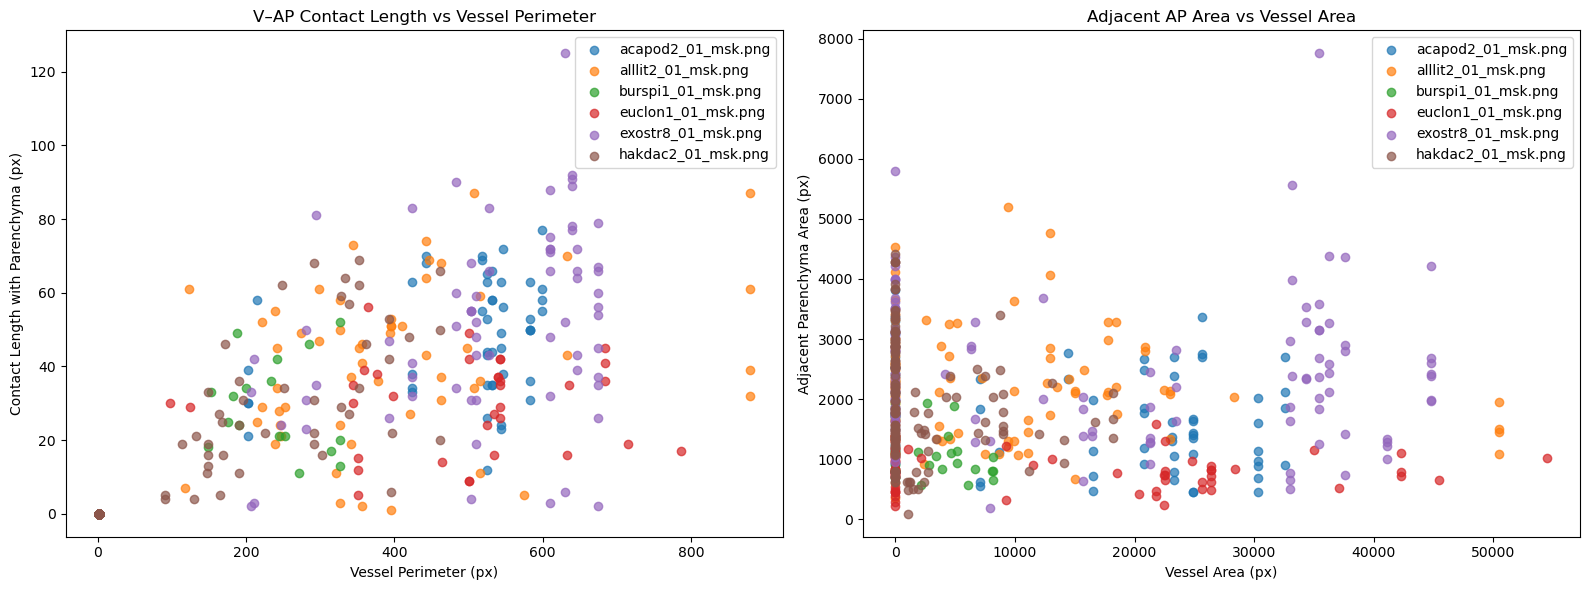

In [4]:
# records の DataFrame があると仮定


# 面積0のvesselを除外
df = df[df['v_area'] > 0.9]




# 可視化①: Vessel perimeter vs contact length
if not df.empty:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    for name, group in df.groupby('image'):
        ax1.scatter(group['v_perim'], group['contact_px'], label=name, alpha=0.7)
    ax1.set_xlabel('Vessel Perimeter (px)')
    ax1.set_ylabel('Contact Length with Parenchyma (px)')
    ax1.set_title('V–AP Contact Length vs Vessel Perimeter')
    ax1.legend()

# 可視化②: Vessel area vs AP area
    for name, group in df.groupby('image'):
        ax2.scatter(group['v_area'], group['ap_area'], label=name, alpha=0.7)
    ax2.set_xlabel('Vessel Area (px)')
    ax2.set_ylabel('Adjacent Parenchyma Area (px)')
    ax2.set_title('Adjacent AP Area vs Vessel Area')
    ax2.legend()

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ V–APエッジが検出されませんでした。")


In [6]:
df_filtered = df[df['v_area'] > 1]

# 必要な列だけに絞って保存
df_filtered[['image', 'v_id', 'ap_id', 'contact_px', 'v_perim', 'v_area', 'ap_area',
             'contact_per_perim', 'ap_area_per_v_area']].to_csv('filtered_edges.csv', index=False)


In [7]:
print(df_filtered)

                  image  v_id  ap_id  contact_px  v_perim   v_area  ap_area  \
5    acapod2_01_msk.png   257    319          63      423  16554.0   1983.0   
6    acapod2_01_msk.png   257    378          38      423  16554.0   1134.0   
7    acapod2_01_msk.png   257    383          34      423  16554.0    478.0   
8    acapod2_01_msk.png   257    399          33      423  16554.0    719.0   
13   acapod2_01_msk.png   343    376          69      518  23152.0   1614.0   
..                  ...   ...    ...         ...      ...      ...      ...   
535  hakdac2_01_msk.png  1052   1091          34      251   5106.0   2033.0   
536  hakdac2_01_msk.png  1069   1091          59      328   8125.0   2033.0   
537  hakdac2_01_msk.png  1072   1104           6      395  13091.0   2270.0   
539  hakdac2_01_msk.png  1177   1186           5       91   1064.0    497.0   
540  hakdac2_01_msk.png  1177   1189           4       91   1064.0     95.0   

     contact_per_perim  ap_area_per_v_area  
5     

## Weighted degree

/tmp/ipykernel_774690/862310862.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['v_radius'] = np.sqrt(df_filtered['v_area'] / np.pi)


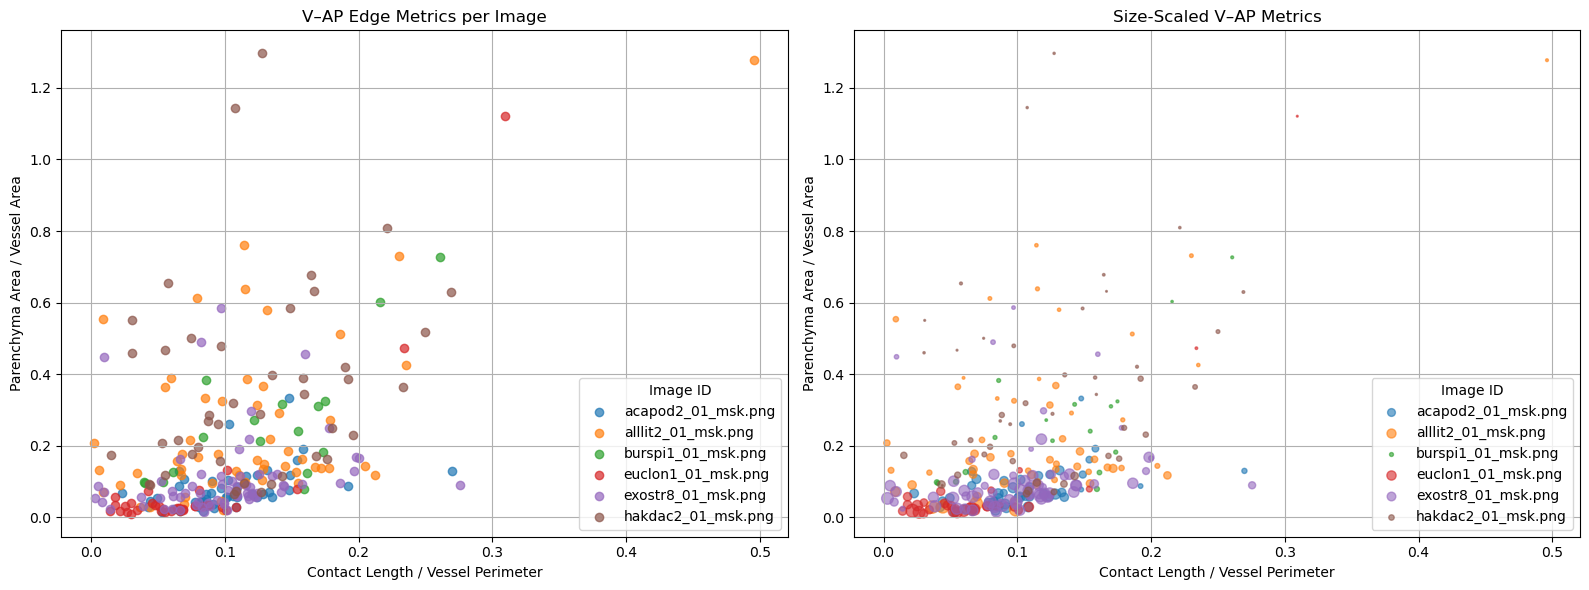

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# 面積から半径を計算（必要であれば）
df_filtered['v_radius'] = np.sqrt(df_filtered['v_area'] / np.pi)

# サブプロット準備
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# サブプロット①: 通常の散布図（点サイズ固定）
for name, group in df_filtered.groupby('image'):
    ax1.scatter(group['contact_per_perim'], group['ap_area_per_v_area'], label=name, alpha=0.7)
ax1.set_xlabel('Contact Length / Vessel Perimeter')
ax1.set_ylabel('Parenchyma Area / Vessel Area')
ax1.set_title('V–AP Edge Metrics per Image')
ax1.legend(title='Image ID')
ax1.grid(True)

# サブプロット②: 点サイズ = vessel 面積に比例
for name, group in df_filtered.groupby('image'):
    ax2.scatter(
        group['contact_per_perim'],
        group['ap_area_per_v_area'],
        s=group['v_radius']**2 * 0.005,  # 半径から点のサイズに変換（調整可）
        label=name,
        alpha=0.6
    )
ax2.set_xlabel('Contact Length / Vessel Perimeter')
ax2.set_ylabel('Parenchyma Area / Vessel Area')
ax2.set_title('Size-Scaled V–AP Metrics')
ax2.legend(title='Image ID')
ax2.grid(True)

plt.tight_layout()
plt.show()


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.preprocessing import MinMaxScaler

# 元データ: df_filtered に全V–AP edgeデータが入っていると仮定
# 必要列: ['image', 'v_id', 'contact_px', 'v_perim', 'v_area', 'ap_area']

# 🔧 追加：全vessel一覧を取得（例：regionpropsなどから得られたdf_propsを使用）
# df_props はマスク画像由来の属性テーブルを想定
df_all_vessels = df_props[['image', 'v_id', 'v_perim', 'v_area']].copy()



# vessel ごとに接触長と AP面積を合計し、1 vessel ごとの統計にする
df_vap_summary = (
    df_filtered
    .groupby(['image', 'v_id'])
    .agg({
        'contact_px': 'sum',
        'ap_area': 'sum'
    })
    .reset_index()
)


# 🔧 修正：全vesselデータとマージ（接触のないvesselも含める）
df_vessel_summary = pd.merge(df_all_vessels, df_vap_summary, on=['image', 'v_id'], how='left')

# 🔧 修正：接触のないvesselには0を代入
df_vessel_summary[['contact_px', 'ap_area']] = df_vessel_summary[['contact_px', 'ap_area']].fillna(0)

# 🔧 以降は元の計算（変える必要なし）
df_vessel_summary['contact_per_perim'] = df_vessel_summary['contact_px'] / df_vessel_summary['v_perim']
df_vessel_summary['ap_area_per_v_area'] = df_vessel_summary['ap_area'] / df_vessel_summary['v_area']
df_vessel_summary['v_radius'] = np.sqrt(df_vessel_summary['v_area'] / np.pi)

scaler = MinMaxScaler()
df_vessel_summary[['contact_norm', 'ap_area_norm']] = scaler.fit_transform(
    df_vessel_summary[['contact_per_perim', 'ap_area_per_v_area']]
)

df_vessel_summary['Integrated Weighted Degree'] = (
    0.5 * df_vessel_summary['contact_norm'] +
    0.5 * df_vessel_summary['ap_area_norm']
)


In [10]:
## df_vessel_summaryを、のちの再利用のために保存

# 保存先フォルダを作成（存在しない場合）
os.makedirs("plots_dfs", exist_ok=True)

# CSV保存
df_vessel_summary.to_csv(
    "plots_dfs/vessel_level_connectivity_summary.csv",
    index=False
)

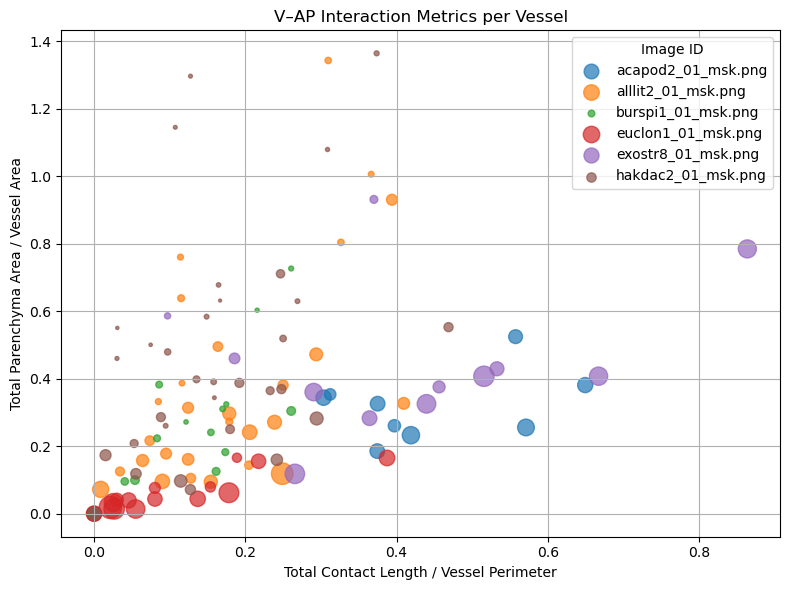

In [11]:


# 散布図プロット
plt.figure(figsize=(8, 6))

for name, group in df_vessel_summary.groupby('image'):
    plt.scatter(
        group['contact_per_perim'],
        group['ap_area_per_v_area'],
        s=group['v_radius']**2 * 0.015,  # 点のサイズは面積に比例
        label=name,
        alpha=0.7
    )
mpl.rcParams['pdf.fonttype'] = 42
plt.xlabel('Total Contact Length / Vessel Perimeter')
plt.ylabel('Total Parenchyma Area / Vessel Area')
plt.title('V–AP Interaction Metrics per Vessel')
plt.legend(title='Image ID')
plt.grid(True)
plt.tight_layout()

save_path = 'plots_dfs/weighted_degree.pdf'

plt.savefig(save_path)  # 高解像度で保存

plt.show()


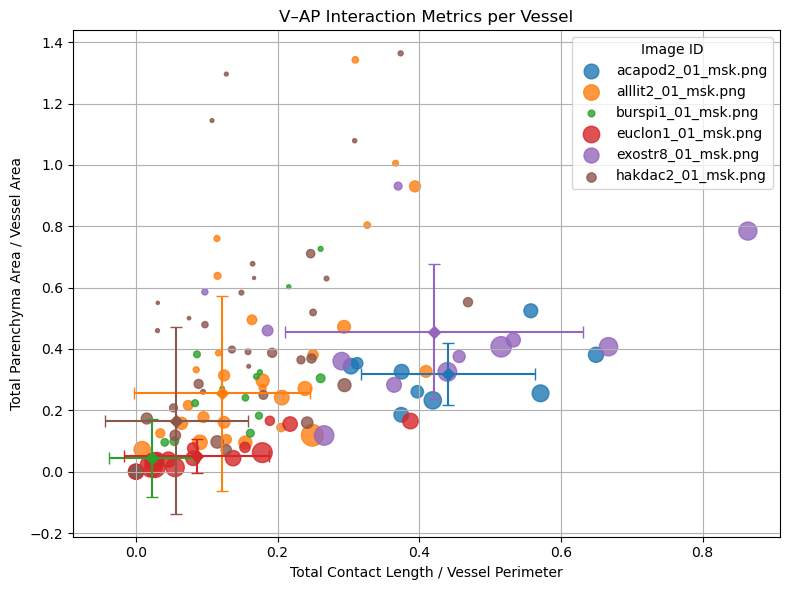

In [10]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import numpy as np

# PDF保存用フォント設定
mpl.rcParams['pdf.fonttype'] = 42

# 色の割り当て（画像ごとに一意に）
color_map = dict(zip(
    df_vessel_summary['image'].unique(),
    mpl.rcParams['axes.prop_cycle'].by_key()['color']
))

# プロット
plt.figure(figsize=(8, 6))

for name, group in df_vessel_summary.groupby('image'):
    color = color_map[name]
    
    # 散布図
    plt.scatter(
        group['contact_per_perim'],
        group['ap_area_per_v_area'],
        s=group['v_radius']**2 * 0.015,
        label=name,
        alpha=0.8,
        color=color
    )


    # 平均値と標準偏差（SD）
    x_mean = group['contact_per_perim'].mean()
    y_mean = group['ap_area_per_v_area'].mean()
    x_std = group['contact_per_perim'].std()
    y_std = group['ap_area_per_v_area'].std()

    # 十字のエラーバー＋ダイヤ型の中心
    plt.errorbar(
        x_mean,
        y_mean,
        xerr=x_std,
        yerr=y_std,
        fmt='D',                  # ダイヤ型
        markersize=6,
        color=color,
        capsize=4,
        elinewidth=1.5,
        label=None
    )

plt.xlabel('Total Contact Length / Vessel Perimeter')
plt.ylabel('Total Parenchyma Area / Vessel Area')
plt.title('V–AP Interaction Metrics per Vessel')
plt.legend(title='Image ID')
plt.grid(True)
plt.tight_layout()

save_path = 'plots_dfs/weighted_degree_mean.pdf'
plt.savefig(save_path)
plt.show()



/tmp/ipykernel_3716959/82225807.py:47: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coef = model.params[1]
/tmp/ipykernel_3716959/82225807.py:48: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept = model.params[0]
/tmp/ipykernel_3716959/82225807.py:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_value = model.pvalues[1]
/tmp/ipykernel_3716959/82225807.py:47: FutureWarning: Series.__getitem__ treating keys as positions is 

📊 acapod2_01_msk.png
  Slope         : 0.2788
  Intercept     : 0.1954
  R²            : 0.1163
  p-value       : 3.6913e-01
  95% CI (slope): [-0.4082, 0.9659]

📊 alllit2_01_msk.png
  Slope         : 1.9227
  Intercept     : 0.0224
  R²            : 0.5609
  p-value       : 1.1692e-08
  95% CI (slope): [1.3791, 2.4664]

📊 burspi1_01_msk.png
  Slope         : 1.9371
  Intercept     : 0.0011
  R²            : 0.8310
  p-value       : 5.9396e-35
  95% CI (slope): [1.7498, 2.1243]

📊 euclon1_01_msk.png
  Slope         : 0.4871
  Intercept     : 0.0084
  R²            : 0.7981
  p-value       : 2.6191e-07
  95% CI (slope): [0.3617, 0.6124]

📊 exostr8_01_msk.png
  Slope         : 0.2632
  Intercept     : 0.3449
  R²            : 0.0633
  p-value       : 4.3010e-01
  95% CI (slope): [-0.4501, 0.9765]

📊 hakdac2_01_msk.png
  Slope         : 2.2595
  Intercept     : 0.0377
  R²            : 0.5612
  p-value       : 8.8493e-18
  95% CI (slope): [1.8411, 2.6779]



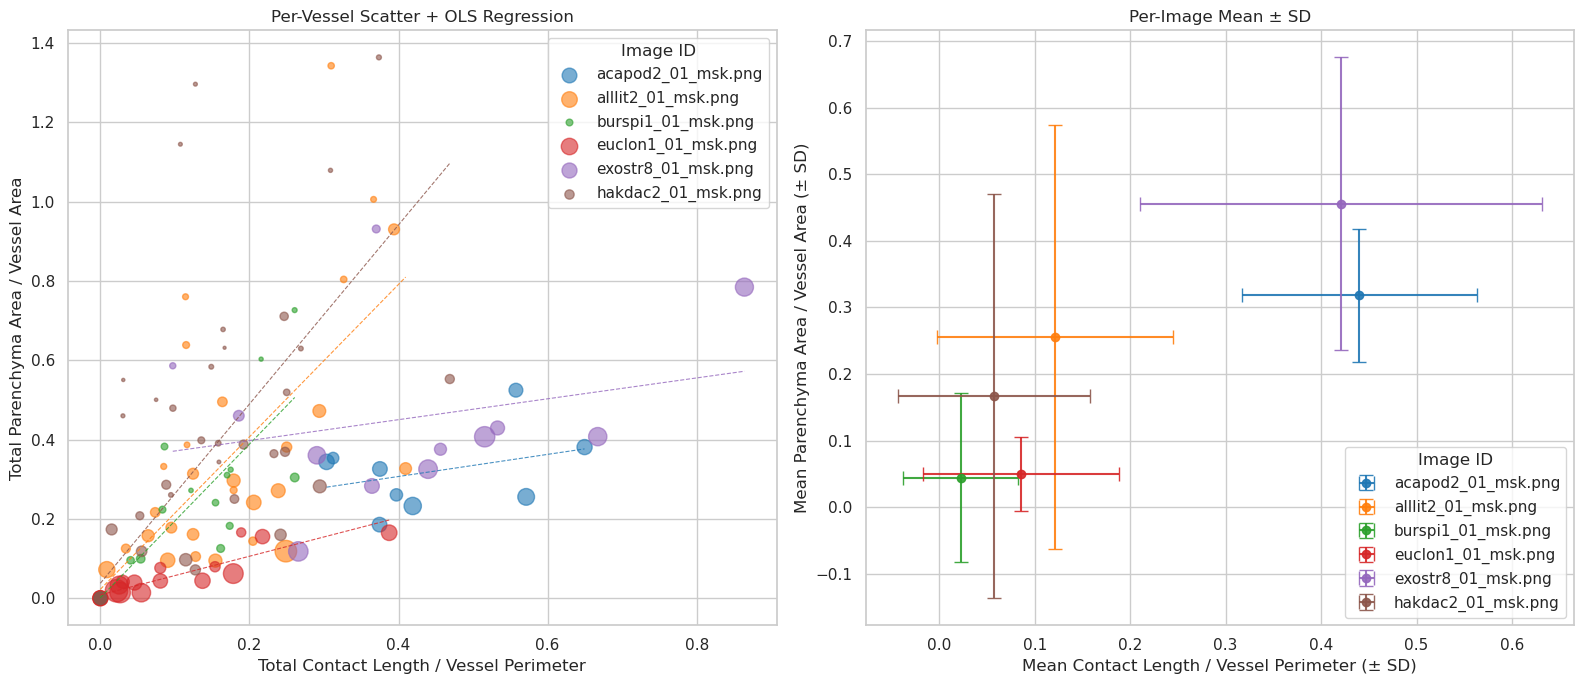

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import matplotlib as mpl

# ---- データ前処理 ----
df_filtered_vsize = df_vessel_summary.copy()
grouped = df_filtered_vsize.groupby('image')

# ---- カラーマップ準備 ----
palette = sns.color_palette('tab10', n_colors=df_filtered_vsize['image'].nunique())
image_list = df_filtered_vsize['image'].unique()
color_dict = {img: palette[i % len(palette)] for i, img in enumerate(image_list)}

# ---- 描画設定 ----
mpl.rcParams['pdf.fonttype'] = 42
sns.set(style="whitegrid")

# ---- フィギュア準備（1行2列）----
fig, axs = plt.subplots(1, 2, figsize=(16, 7), sharex=False, sharey=False)

# ------------------------
# プロット①：散布図＋回帰線
# ------------------------
for name, group in grouped:
    color = color_dict[name]

    # 散布図
    axs[0].scatter(
        group['contact_per_perim'],
        group['ap_area_per_v_area'],
        s=group['v_radius']**2 * 0.015,
        alpha=0.6,
        label=name,
        color=color
    )

    # 回帰線（OLS）
    if len(group) > 2:
        x = group['contact_per_perim']
        y = group['ap_area_per_v_area']
        X = sm.add_constant(x)
        model = sm.OLS(y, X).fit()

        coef = model.params[1]
        intercept = model.params[0]
        r2 = model.rsquared
        p_value = model.pvalues[1]
        lower, upper = model.conf_int().iloc[1]

        # 回帰線描画（線のみ）
        sns.regplot(
            x=x,
            y=y,
            scatter=False,
            ci=None,
            line_kws={
                "linestyle": "--",
                "linewidth": 0.8,
                "alpha": 0.8,
                "color": color
            },
            ax=axs[0]
        )

        # 統計情報出力
        print(f"📊 {name}")
        print(f"  Slope         : {coef:.4f}")
        print(f"  Intercept     : {intercept:.4f}")
        print(f"  R²            : {r2:.4f}")
        print(f"  p-value       : {p_value:.4e}")
        print(f"  95% CI (slope): [{lower:.4f}, {upper:.4f}]\n")

axs[0].set_xlabel('Total Contact Length / Vessel Perimeter')
axs[0].set_ylabel('Total Parenchyma Area / Vessel Area')
axs[0].set_title('Per-Vessel Scatter + OLS Regression')
axs[0].legend(title='Image ID', loc='best')
axs[0].grid(True)

# ------------------------
# プロット②：平均±SDプロット
# ------------------------
for name, group in grouped:
    color = color_dict[name]

    # 平均と標準偏差
    x_mean = group['contact_per_perim'].mean()
    y_mean = group['ap_area_per_v_area'].mean()
    x_std = group['contact_per_perim'].std()
    y_std = group['ap_area_per_v_area'].std()

    axs[1].errorbar(
        x_mean, y_mean,
        xerr=x_std, yerr=y_std,
        fmt='o',
        color=color,
        label=name,
        capsize=5,
        alpha=0.9
    )

axs[1].set_xlabel('Mean Contact Length / Vessel Perimeter (± SD)')
axs[1].set_ylabel('Mean Parenchyma Area / Vessel Area (± SD)')
axs[1].set_title('Per-Image Mean ± SD')
axs[1].legend(title='Image ID', loc='best')
axs[1].grid(True)

# ---- 全体整形 ----
plt.tight_layout()
plt.savefig('plots_dfs/weighted_degree_regression_plus_meanSD.pdf')
plt.show()


In [18]:
# ------------------------
# 平均±SDを DataFrame にまとめて保存
# ------------------------
summary_list = []

for name, group in grouped:
    summary_list.append({
        "image": name,
        "contact_per_perim_mean": group['contact_per_perim'].mean(),
        "contact_per_perim_sd": group['contact_per_perim'].std(),
        "ap_area_per_v_area_mean": group['ap_area_per_v_area'].mean(),
        "ap_area_per_v_area_sd": group['ap_area_per_v_area'].std(),
        "n_vessels": len(group)  # 参考：サンプル数
    })

df_meansd = pd.DataFrame(summary_list)

# CSVに保存
df_meansd.to_csv("plots_dfs/weighted_degree_image_meanSD.csv", index=False)
print("Saved -> plots_dfs/weighted_degree_image_meanSD.csv")
print(df_meansd.head())


Saved -> plots_dfs/weighted_degree_image_meanSD.csv
                image  contact_per_perim_mean  contact_per_perim_sd  \
0  acapod2_01_msk.png                0.439950              0.122809   
1  alllit2_01_msk.png                0.121360              0.123953   
2  burspi1_01_msk.png                0.022240              0.059900   
3  euclon1_01_msk.png                0.085713              0.102367   
4  exostr8_01_msk.png                0.420732              0.210418   

   ap_area_per_v_area_mean  ap_area_per_v_area_sd  n_vessels  
0                 0.318100               0.100421          9  
1                 0.255708               0.318233         42  
2                 0.044202               0.127284         88  
3                 0.050140               0.055813         19  
4                 0.455686               0.220099         12  
